# Avaliação de Casos de Reclamações em Entregas

# Objetivos

1. Realizar uma **Análise Exploratória** para identificar padrões e responder questões de negócio.

In [1]:
# Imports
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

# adiciona diretório raiz do projeto ao sys.path
sys.path.insert(0, str(Path.cwd().parent))

# configurações gerais
pd.set_option('display.max_rows', None)
sns.set_theme(style='whitegrid', palette='pastel')
%matplotlib inline

# 1. Carga dos Dados

In [2]:
data_path = Path.cwd().parent / 'data' / 'Relatorio_Entregas.xlsx'

raw_data = pd.read_excel(
    data_path,
    engine='openpyxl'
)

print(f"Dataset carregado de: {data_path}")
print("\n========= Dimensões do Dataset =========\n")
print(f"Número de Linhas: {raw_data.shape[0]}")
print(f"Número de Colunas: {raw_data.shape[1]}")
raw_data.head()

Dataset carregado de: c:\Users\jooar\ds\LABS\data-analisys-labs\data-analisys-labs\projects\avaliacao-casos-reclamacao-entregas\data\Relatorio_Entregas.xlsx

========= Dimensões do Dataset =========

Número de Linhas: 1000
Número de Colunas: 8


,ID_viagem,numero_entregas,tipo_caminhao,produto,Distância,numero_dias,numero_paradas_motorista,Reclamação
0,TRIP-000001,2,Tanque grande,Produto B,268,1,6,Não
1,TRIP-000002,1,Tanque médio,Produto D,154,1,4,Sim
2,TRIP-000003,6,Tanque médio,Produto D,140,1,3,Sim
3,TRIP-000004,2,Tanque médio,Produto A,140,1,5,Não
4,TRIP-000005,28,Tanque grande,Produto A,576,2,10,Não


## 1.1 Visão Geral do Dataset

**Descrição**: O dataset contém informações de entregas que foram realizadas durante **três meses**. Cada linha corresponde a uma entrega e é indentificada por uma ID única.

| Campo | Descrição |
|---|---|
| `ID da viagem` | Código identificador único da viagem. |
| `Número de entregas` | Quantidade de entregas realizadas na viagem. |
| `Tipo de caminhão` | Tipo de caminhão usado no transporte. |
| `Produto` | Produto transportado; cada viagem entrega um único tipo de produto. |
| `Distância` | Distância total percorrida no trajeto em km. |
| `Número de dias` | Duração total da viagem, em dias. |
| `Número de paradas do motorista` | Quantidade de paradas durante a viagem, por qualquer motivo. |
| `Reclamação` | Indicação de existência de reclamação associada à viagem. |


Antes de seguirmos com as análises é importante fazer uma verificação na qualidade dos dados (**Sanity Check**), vamos verificar:
- a presença de dados duplicados;
- verificar se há dados nulos ou inválidos;
- a presença de outliers.

In [3]:
# informações gerais sobre o dataset
print("========= Informações do Dataset =========\n")
raw_data.info()

print("\n========= Dados Duplicados =========")
dados_duplicados = raw_data.duplicated().sum()
print(f"Número de linhas duplicadas: {dados_duplicados}")

========= Informações do Dataset =========

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   ID_viagem                 1000 non-null   str  
 1   numero_entregas           1000 non-null   int64
 2   tipo_caminhao             1000 non-null   str  
 3   produto                   1000 non-null   str  
 4   Distância                 1000 non-null   int64
 5   numero_dias               1000 non-null   int64
 6   numero_paradas_motorista  1000 non-null   int64
 7   Reclamação                1000 non-null   str  
dtypes: int64(4), str(4)
memory usage: 62.6 KB

========= Dados Duplicados =========
Número de linhas duplicadas: 0


**Não foram identificados valores nulos ou duplicados na base**. Seguindo na investigação, será verificado se há valores inválidos e outliers na base.

In [4]:
#dropando a variável ID_viagem, pois não é relevante para a análise
new_data = raw_data.drop(columns=['ID_viagem'])

# separando as variáveis numéricas e categóricas
num_vars = [col for col in new_data.columns if new_data[col].dtype == 'int64']
cat_vars = [col for col in new_data.columns if new_data[col].dtype == 'str']

print("=========== Granularidade das Variáveis Categóricas ===========\n")
print(new_data[cat_vars].nunique())
print('\n========= Valores Únicos das Variáveis Categóricas =========\n')
for var in cat_vars:
    print(f"{var}: {new_data[var].unique().tolist()}")

print("\n=========== Estatísticas Descritivas das Variáveis Numéricas ===========\n")
print(new_data[num_vars].describe())


print("\n=========== Percentual de Outliers nas Variáveis Numéricas ===========\n")
for var in num_vars:
    Q1 = new_data[var].quantile(0.25)
    Q3 = new_data[var].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = new_data[(new_data[var] < lower_bound) | (new_data[var] > upper_bound)]
    outlier_percentage = (len(outliers) / len(new_data)) * 100
    print(f"{var}: {outlier_percentage:.2f}% de outliers")

=========== Granularidade das Variáveis Categóricas ===========

tipo_caminhao    3
produto          4
Reclamação       2
dtype: int64

========= Valores Únicos das Variáveis Categóricas =========

tipo_caminhao: ['Tanque grande', 'Tanque médio', 'Tanque pequeno']
produto: ['Produto B', 'Produto D', 'Produto A', 'Produto C']
Reclamação: ['Não', 'Sim']

=========== Estatísticas Descritivas das Variáveis Numéricas ===========

       numero_entregas    Distância  numero_dias  numero_paradas_motorista
count      1000.000000  1000.000000  1000.000000               1000.000000
mean          6.097000   232.322000     1.104000                  4.787000
std           8.827316   180.235105     0.351151                  2.324873
min           1.000000    50.000000     1.000000                  1.000000
25%           2.000000    94.750000     1.000000                  3.000000
50%           3.000000   183.000000     1.000000                  5.000000
75%           6.000000   311.250000     1.0000

Após a verificação, **não foram identificados valores inválidos ou inconsistências** aparentes nas variáveis analisadas. A variável binária apresentou duas categorias distintas, conforme esperado, enquanto **as demais variáveis categóricas apresentaram valores coerentes com seus respectivos domínios**, sem indícios de erros de digitação ou classificações inadequadas.

Em relação as **variáveis numéricas**, as variáveis `numero_entregas` e `numero_dias` apresentaram uma quantidade considerável de outliers estatísticos. Embora esses outliers não representem uma inconsistencia nos dados eles podem distorcer métricas de tendência central como a média. Dessa forma, é importante considerar outras métricas para resumir os dados destas variáveis.

A classificação das variáveis é a seguinte:
- **Qualitativas Nominais**: `tipo_caminhao` e `produto`.
- **Qualitativa Binária**: `Reclamação`.
- **Quantitativa Discreta**: `numero_entregas`, `Distância`, `numero_dias` e `numero_paradas_motorista`

# 2. Q&A - respondendo perguntas de negócio

### Q1 - Em uma reunião o chefe de logística disse que mais da metade das viagens fazem mais do que 6 entregas. Essa informação está correta?

Com base nos resultados, **não há evidências de que mais da metade das viagens faça mais de 6 entregas**. O valor mediano foi de 3 entregas, o que indica que pelo menos metade das viagens fez até 3 entregas e pelo menos metade fez 3 ou mais. 

A média foi de 6,10 entregas, mas ela não significa que a maioria das viagens tenha feito mais de 6. A diferença entre média e mediana sugere que valores altos estão elevando a média. Isso é compatível com a presença de quase 10% de outliers estatísticos e com a distância entre o terceiro quartil (Q3 = 6) e o valor máximo (50). Por isso, a mediana é mais representativa do centro desta distribuição do que a média.

Assim, é possível que o gestor tenha usado a média para resumir os dados e interpretado esse valor como se representasse a maioria das viagens equivocadamente.

A métrica que responde essa pergunta é a **mediana**. Ela corresponde ao **valor central da base ordenada** onde metade das observações fica abaixo dela e metade acima. Como complemento, podemos plotar o gráfico ***boxplot*** para verificar a distribuição dessa variável.

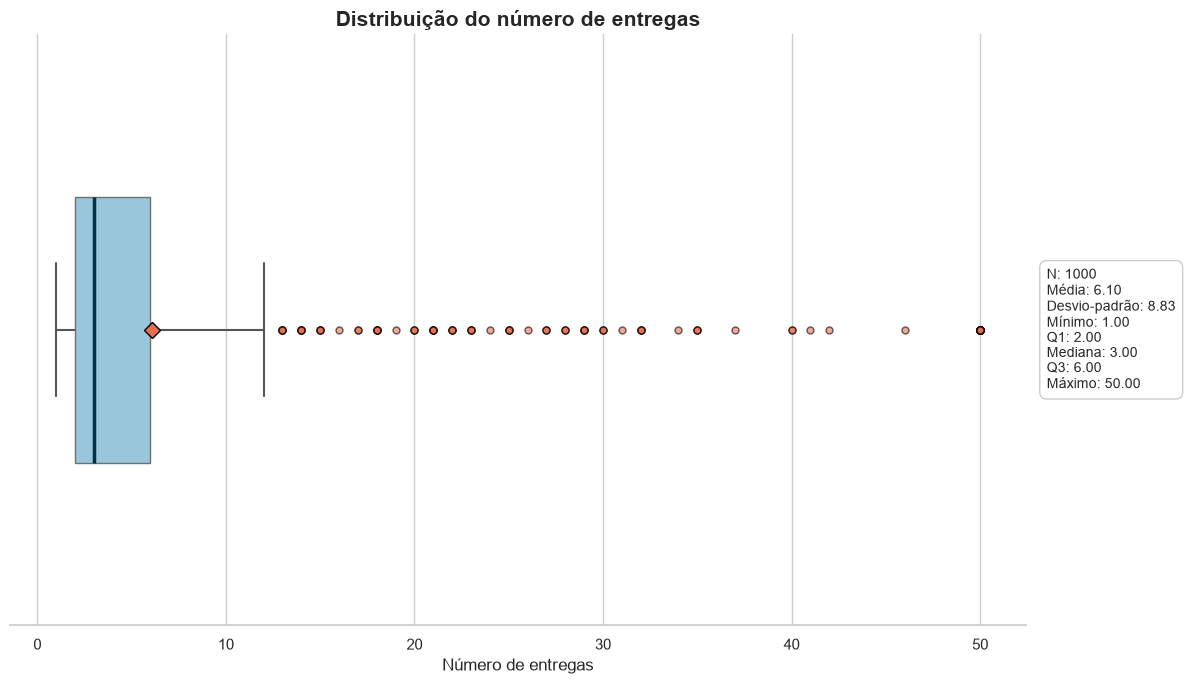

In [5]:
df = new_data.copy()

coluna = "numero_entregas"
dados = df[coluna]
medidas = dados.describe()

sns.set_theme(style="whitegrid", palette="deep")

fig, ax = plt.subplots(figsize=(12, 7))

sns.boxplot(
    x=dados,
    ax=ax,
    color="#8ecae6",
    width=0.45,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#e76f51",
        "markeredgecolor": "black",
        "markersize": 8,
    },
    medianprops={"color": "#023047", "linewidth": 2.5},
    whiskerprops={"color": "#555555", "linewidth": 1.5},
    capprops={"color": "#555555", "linewidth": 1.5},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#e76f51",
        "markeredgecolor": "black",
        "markersize": 5,
        "alpha": 0.6,
    },
)

ax.set_title("Distribuição do número de entregas", fontsize=15, weight="bold")
ax.set_xlabel("Número de entregas")
ax.set_ylabel("")
ax.spines[["top", "right", "left"]].set_visible(False)

resumo = (
    f"N: {medidas['count']:.0f}\n"
    f"Média: {medidas['mean']:.2f}\n"
    f"Desvio-padrão: {medidas['std']:.2f}\n"
    f"Mínimo: {medidas['min']:.2f}\n"
    f"Q1: {medidas['25%']:.2f}\n"
    f"Mediana: {medidas['50%']:.2f}\n"
    f"Q3: {medidas['75%']:.2f}\n"
    f"Máximo: {medidas['max']:.2f}"
)

ax.text(
    1.02, 0.5, resumo,
    transform=ax.transAxes,
    va="center",
    fontsize=10,
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": "#cccccc"},
)

plt.tight_layout()
plt.show()

### Q2 - Existe alguma correlação aparente entre o número de entregas e a distância percorrida?

O gráfico mostra uma **associação linear positiva forte** entre o número de entregas e a distância percorrida (correlação de Pearson: r = 0,734). Em geral, **viagens com mais entregas tendem a apresentar distâncias maiores**. Essa associação é aparente no padrão ascendente da nuvem de pontos, mas não demonstra uma relação de causa e efeito.

Também há **observações concentradas no limite de 50 entregas**, com distâncias próximas de 750 a 1.050 km. Esses valores merecem investigação, pois **podem influenciar a correlação** e foram sinalizados como possíveis outliers na etapa de *Sanity Check*. Recomenda-se verificar com a área de negócio se representam viagens válidas, limites de registro ou possíveis inconsistências nos dados antes de tirar conclusões sobre esses casos.

Para investigar a relação entre o número de entregas e a distância percorrida em cada viagem, será construído um gráfico de dispersão. Como ambas são variáveis quantitativas, o gráfico permite observar a distribuição conjunta dos valores e verificar se os pontos sugerem uma tendência crescente ou decrescente, um padrão aproximadamente linear ou a ausência de um padrão evidente.

A inspeção visual será complementada pelo cálculo da correlação de Pearson, que resume a direção e a intensidade da **associação linear** entre as duas variáveis. O coeficiente será calculado com os registros que tenham valores disponíveis para ambas:

$$
r_{XY} =
\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{
\sum_{i=1}^{n}(x_i-\bar{x})^2
\sum_{i=1}^{n}(y_i-\bar{y})^2
}}
$$

Em que:

- $r_{XY}$ é a correlação de Pearson entre o número de entregas ($X$) e a distância ($Y$);
- $x_i$ e $y_i$ são os valores observados na viagem $i$;
- $\bar{x}$ e $\bar{y}$ são as médias das duas variáveis;
- $n$ é o número de viagens com valores disponíveis para ambas as variáveis.

O coeficiente varia de −1 a +1. Valores próximos de +1 indicam associação linear positiva; valores próximos de −1 indicam associação linear negativa; e valores próximos de 0 indicam pouca ou nenhuma associação linear. Como referência geral, valores absolutos abaixo de 0,3 podem ser descritos como fracos, de 0,3 a 0,7 como moderados e acima de 0,7 como fortes. Esses limites são orientativos e devem ser interpretados junto ao gráfico e ao contexto dos dados.

A correlação de Pearson não descreve relações não lineares e pode ser influenciada por valores extremos. Além disso, uma associação entre número de entregas e distância não demonstra que uma variável cause a outra.

> Para calcular a correlação de pearson entre as variáveis, vou utilizar o método `corr()`.

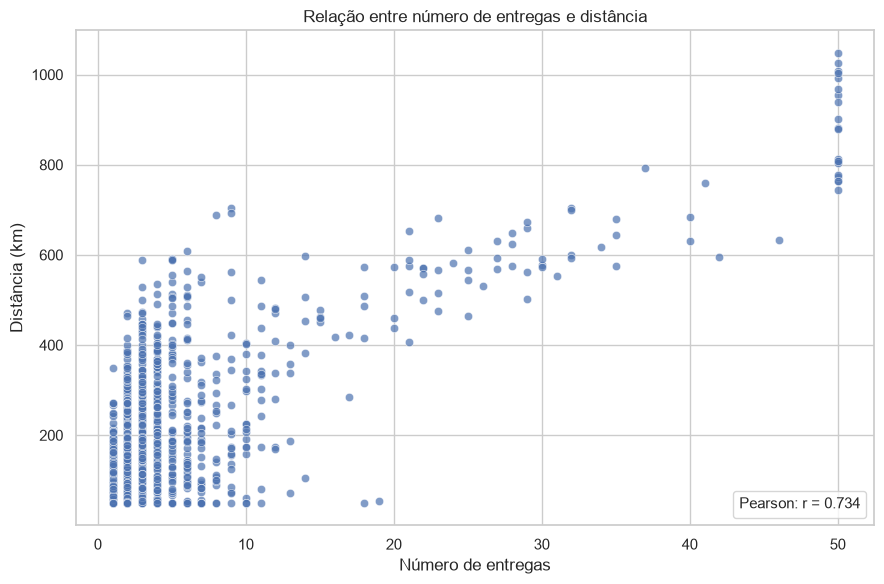

In [6]:
colunas = ["numero_entregas", "Distância"]
dados = df[colunas]

correlacao_pearson = dados["numero_entregas"].corr(dados["Distância"], method="pearson")

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=dados, x="numero_entregas", y="Distância", ax=ax, alpha=0.7)
ax.set_title("Relação entre número de entregas e distância")
ax.set_xlabel("Número de entregas")
ax.set_ylabel("Distância (km)")
ax.legend(
    handles=[plt.Line2D([], [], linestyle="none", label=f"Pearson: r = {correlacao_pearson:.3f}")],
    loc="lower right",
    frameon=True,
    handlelength=0,
    handletextpad=0,
)
plt.tight_layout()
plt.show()

### Q3 - Existe alguma relação entre o tipo de produto entregue e a existência de reclamações?

Na análise realizada, o IV de `produto` foi **0,42**, valor que sugere uma **associação forte** segundo as faixas de referência adotadas. O produto D apresentou a maior taxa observada de reclamações (**58%**), seguido do produto C (**46,72%**). Esses resultados indicam que as taxas variam entre produtos e justificam uma investigação operacional complementar. Como as taxas podem ser menos estáveis em categorias com poucas viagens, sua interpretação deve considerar o número de observações de cada produto. Para avaliar formalmente se as diferenças observadas são compatíveis com uma associação na população, seria necessário aplicar um teste de associação, como o **qui-quadrado**, verificando suas condições de uso.


Para investigar se o tipo de produto entregue está associado à existência de reclamações, comparamos duas variáveis categóricas: `produto`, que identifica o produto transportado na viagem, e `Reclamação`, que indica se houve reclamação. Como a reclamação é binária, usamos o *Information Value* (IV) como medida exploratória da capacidade de cada categoria de produto de separar viagens com e sem reclamação.

Para cada produto \(i\), calculamos o *Weight of Evidence* (WoE) com base na proporção de viagens com reclamação e sem reclamação:

$$
\mathrm{WoE}_i =
\ln\left(
\frac{\%\,\mathrm{sem\ reclamação}_i}
{\%\,\mathrm{com\ reclamação}_i}
\right)
$$

Em seguida, somamos as contribuições de cada categoria para obter o IV:

$$
\mathrm{IV} =
\sum_i
\left(
\%\,\mathrm{sem\ reclamação}_i -
\%\,\mathrm{com\ reclamação}_i
\right)
\times \mathrm{WoE}_i
$$

Os percentuais são calculados em relação ao total de viagens de cada grupo de resposta (com reclamação ou sem reclamação). Assim, o IV resume o quanto a distribuição dos produtos difere entre esses dois grupos. Ele é uma medida descritiva e exploratória que ajuda a avaliar a associação, mas não demonstra que o produto cause reclamações.

Os valores de IV foram interpretados de forma aproximada segundo as faixas abaixo:
| Faixa de IV | Interpretação |
|:---:|:---:|
| < 0,02 | Muito fraco |
| Entre 0,02 e 0,10 | Fraco |
| Entre 0,10 e 0,30 | Médio |
| Entre 0,30 e 0,50 | Forte |
| Maior que 0,50 | Suspeito ou muito alto; recomenda-se verificar |

Para os cálculos, usamos a classe `AnaliseIV`, do módulo `src/analise_IV.py`. O método `get_iv_list()` apresenta as variáveis em ordem decrescente de IV; `get_freq_table()` detalha, para cada categoria, as frequências observadas, os percentuais por grupo, o WoE e a contribuição ao IV. Também comparamos as taxas observadas de reclamação por produto, pois o IV sozinho não mostra diretamente qual produto tem a maior taxa.

> **Nota 1:**
> Quando uma categoria não possui observações em uma das classes (“Sim” ou “Não”), a implementação adiciona uma **correção de 0,5** às contagens dessa categoria para calcular o WoE e o IV. As frequências e os percentuais apresentados na tabela permanecem baseados nas contagens observadas.

> **Nota 2:**
> É fundamental levar em consideração o **número de observações em cada categoria**, pois isso resulta em uma maior ou menor **confiança na estimativa da frenquência** obtida (teoria frequentista).

In [7]:
from src.analise_IV import AnaliseIV

use_cols = ['produto']

analise = AnaliseIV(
    df=df,
    use_cols=use_cols,
    target='Reclamação'
)

display(analise.get_freq_table('produto'))

col_0,Não,Sim,Total,Freq Rel (%),% Não,% Sim,Taxa Evento (%),WoE,IV Parcial
produto,,,,,,,,,
Produto A,320,68,388,38.8,43.90,25.09,17.53,0.5593,0.1052
Produto B,304,91,395,39.5,41.70,33.58,23.04,0.2166,0.0176
Produto C,65,57,122,12.2,8.92,21.03,46.72,-0.8582,0.1040
Produto D,40,55,95,9.5,5.49,20.30,57.89,-1.3080,0.1937
Total,729,271,1000,100.0,100.00,100.00,27.10,NaN,0.4204


Antes de escrever as conclusões é importante explicar uma diferença entre `% Sim` e `Taxa Evento` contidas nas tabelas de frequências geradas pelo `get_freq_table()`.

- **Percentual de Eventos (% Sim)**: Representa a participação de cada categoria no total de eventos observados na base de dados.

    $$
    \%Sim_i = \frac{Sim_i}{\sum_i Sim_i} \times 100
    $$

    Responde:***"Do total de clientes que reclamaram, qual percentual pertence a essa categoria?"***

- **Taxa de Eventos**: Representa a proporção de eventos observados dentro de uma determinada categoria.

    $$
    TaxaEvento_i = \frac{Sim_i}{Total_i} \times 100
    $$

    Responde: ***"Entre os clientes desta categoria, qual percentual reclamou?"***

### Q4 - Existe alguma relação entre a distância e a existência de reclamações?

O IV de 0,0364 indica que a distância tem **baixo poder para diferenciar casos com e sem reclamação**, e as taxas por faixa não mostram uma tendência consistente. Além disso, **acima de 650 km há apenas 33 casos**, distribuídos em faixas com 4 a 12 observações; por isso, suas taxas são instáveis e devem ser interpretadas com cautela (teoria frequentista). Em conjunto, **os resultados não sustentam uma relação clara entre distância e reclamação**.

A variável `Distância` será agrupada em faixas de 100 km, e cada faixa será comparada com a variável `Reclamação`. Para cada categoria, vamos calcular a distribuição dos casos, a taxa de resolução e o *Weight of Evidence* para entender a relação entre essas variáveis.

> **Nota**: A metodologia segue a da questão 3. A diferença é que como estamos comparando uma variável numérica quantitativa discreta, precisamos agrupá-las em um processo chamado **discretização**.

In [8]:
# Separando as Faixas de Distância
limites = list(range(50, 1051, 100))
rotulos = [f"{inicio}-{inicio + 99}" for inicio in range(50, 1050, 100)]

df["faixa_distancia"] = pd.cut(
    df["Distância"],
    bins=limites,
    labels=rotulos,
    right=False
)

# Analisando a variável Faixa_Distância em relação à variável Resolução
use_cols = ['faixa_distancia']
analise_tempo_espera = AnaliseIV(
    df=df,
    use_cols=use_cols,
    target='Reclamação'
)

display(analise_tempo_espera.get_freq_table('faixa_distancia'))

col_0,Não,Sim,Total,Freq Rel (%),% Não,% Sim,Taxa Evento (%),WoE,IV Parcial
faixa_distancia,,,,,,,,,
50-149,295,111,406,40.6,40.47,40.96,27.34,-0.0121,0.0001
150-249,179,65,244,24.4,24.55,23.99,26.64,0.0234,0.0001
250-349,98,43,141,14.1,13.44,15.87,30.50,-0.1658,0.0040
350-449,67,23,90,9.0,9.19,8.49,25.56,0.0796,0.0006
450-549,30,16,46,4.6,4.12,5.90,34.78,-0.3609,0.0065
550-649,33,7,40,4.0,4.53,2.58,17.50,0.5610,0.0109
650-749,9,3,12,1.2,1.23,1.11,25.00,0.1091,0.0001
750-849,9,1,10,1.0,1.23,0.37,10.00,1.2077,0.0105
850-949,3,1,4,0.4,0.41,0.37,25.00,0.1091,0.0000


### Q5 - Como os dados de Distância estão distribuidos por tipo de produto?

As distribuições de distância são, em geral, semelhantes entre os tipos de produto. Os produtos A, B e C apresentam medianas próximas (entre 181,5 e 189), assim como médias semelhantes (entre 226,5 e 233,7). O produto D tem a menor mediana (158), mas sua média (230,2) permanece próxima à dos demais, e sua caixa apresenta maior amplitude. Há outliers em todas as categorias, com quantidades e valores que variam.

Assim, **a comparação visual não mostra uma diferença marcante que permita afirmar que o tipo de produto esteja associado a maiores distâncias percorridas**.

Para analisar como as distâncias variam por tipo de produto, foram construídos **boxplots** separados para cada categoria. A comparação considerou a mediana, a média, a amplitude interquartil (o tamanho da caixa), a dispersão dos valores e a presença de observações atípicas. Essa análise visual permite comparar a distribuição das distâncias entre os tipos de produto e identificar diferenças de tendência central e variabilidade.

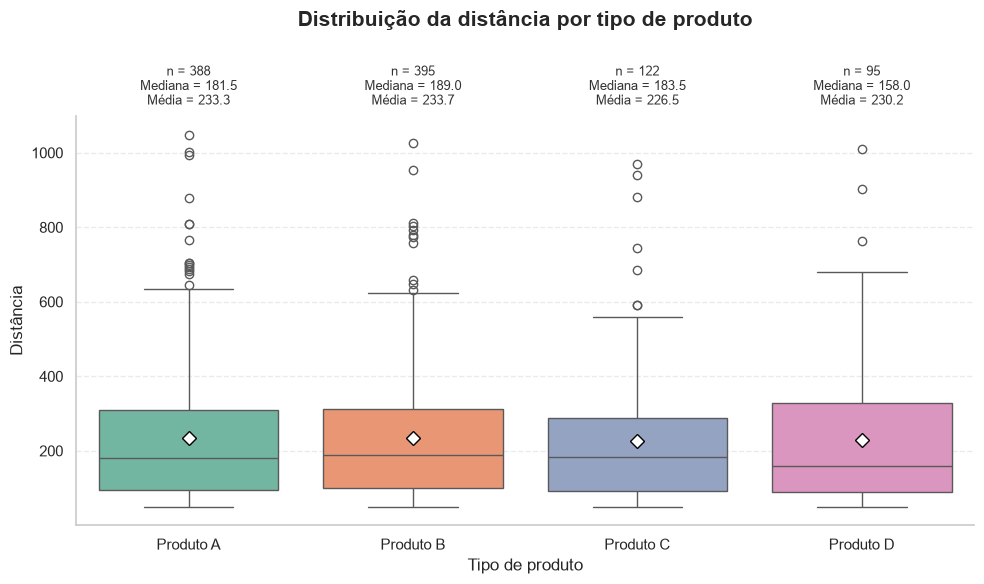

In [9]:
ordem = sorted(df["produto"].unique())
cores = dict(zip(ordem, sns.color_palette("Set2", n_colors=len(ordem))))

# Remove linhas sem dados nas duas variáveis
dados_plot = df[["produto", "Distância"]]

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=dados_plot,
    x="produto",
    y="Distância",
    hue="produto",
    order=ordem,
    hue_order=ordem,
    palette=cores,
    legend=False,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7,
    },
    ax=ax,
)

# Anota quantidade, mediana e média acima de cada caixa
for posicao, produto in enumerate(ordem):
    grupo = dados_plot.loc[
        dados_plot["produto"] == produto,
        "Distância",
    ]

    if grupo.empty:
        continue

    mediana = grupo.median()
    media = grupo.mean()
    quantidade = grupo.count()

    ax.annotate(
        f"n = {quantidade}\nMediana = {mediana:.1f}\nMédia = {media:.1f}",
        xy=(posicao, 1.02),
        xycoords=("data", "axes fraction"),
        ha="center",
        va="bottom",
        fontsize=9,
        color="#333333",
    )

ax.set_title(
    "Distribuição da distância por tipo de produto",
    fontsize=15,
    fontweight="bold",
    pad=65,
)
ax.set_xlabel("Tipo de produto")
ax.set_ylabel("Distância")
ax.grid(axis="y", linestyle="--", alpha=0.4)
sns.despine()

plt.tight_layout()
plt.show()

### Q6 - Você diria que há associaçao aparente entre as variáveis de reclamações e número de paradas do motorista?

O boxplot mostra distribuições do número de paradas semelhantes para entregas com e sem reclamação. Embora a mediana seja ligeiramente maior entre as entregas com reclamação (5, contra 4), o η² de 0,002 indica que as diferenças entre os grupos estão associadas a apenas 0,196% da variabilidade no número de paradas — uma parcela muito pequena. Desse modo, os resultados sugerem uma **associação aparente muito fraca entre o número de paradas e a ocorrência de reclamação**.

Para avaliar se há uma associação aparente entre o tipo de reclamação e o número de paradas do motorista, foram comparadas as distribuições do número de paradas entre as categorias de reclamação por meio de boxplots. A análise visual considerou a mediana, a média, a amplitude interquartil, a dispersão e a presença de valores atípicos. Como complemento, calculou-se o eta ao quadrado (η²), medida que indica a proporção da variabilidade do número de paradas associada às diferenças entre as categorias de reclamação.

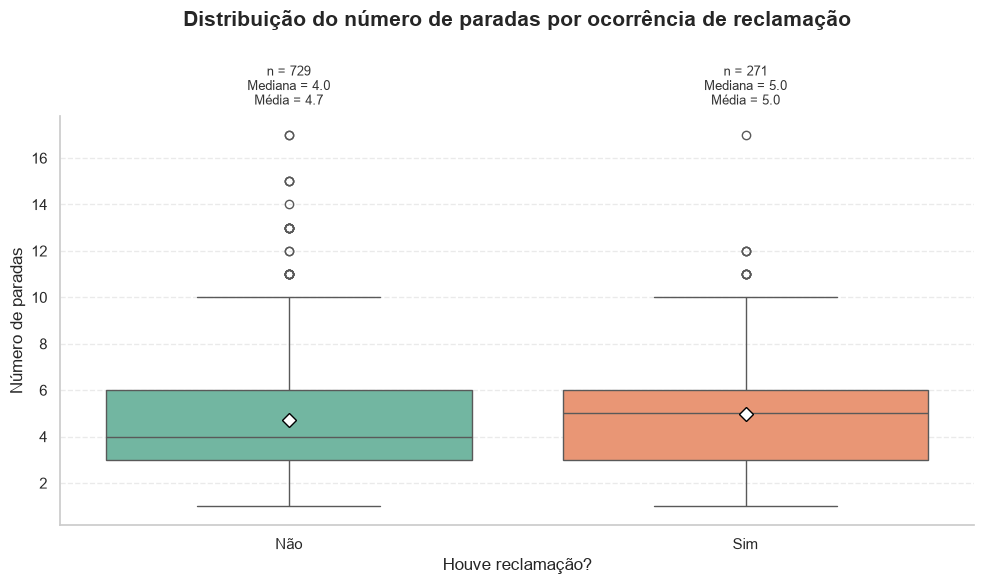

In [10]:
ordem = sorted(df["Reclamação"].dropna().unique())
cores = dict(zip(ordem, sns.color_palette("Set2", n_colors=len(ordem))))

# Remove linhas sem dados nas duas variáveis
dados_plot = df[["Reclamação", "numero_paradas_motorista"]].dropna()

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=dados_plot,
    x="Reclamação",
    y="numero_paradas_motorista",
    hue="Reclamação",
    order=ordem,
    hue_order=ordem,
    palette=cores,
    legend=False,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7,
    },
    ax=ax,
)

# Anota quantidade, mediana e média acima de cada caixa
for posicao, reclamacao in enumerate(ordem):
    grupo = dados_plot.loc[
        dados_plot["Reclamação"] == reclamacao,
        "numero_paradas_motorista",
    ]

    if grupo.empty:
        continue

    ax.annotate(
        f"n = {grupo.count()}\nMediana = {grupo.median():.1f}\nMédia = {grupo.mean():.1f}",
        xy=(posicao, 1.02),
        xycoords=("data", "axes fraction"),
        ha="center",
        va="bottom",
        fontsize=9,
        color="#333333",
    )

ax.set_title(
    "Distribuição do número de paradas por ocorrência de reclamação",
    fontsize=15,
    fontweight="bold",
    pad=65,
)
ax.set_xlabel("Houve reclamação?")
ax.set_ylabel("Número de paradas")
ax.grid(axis="y", linestyle="--", alpha=0.4)
sns.despine()

plt.tight_layout()
plt.show()

In [11]:
dados_eta = df[["Reclamação", "numero_paradas_motorista"]]

media_geral = dados_eta["numero_paradas_motorista"].mean()

# Soma dos quadrados entre os grupos
sq_entre = sum(
    len(grupo) * (grupo["numero_paradas_motorista"].mean() - media_geral) ** 2
    for _, grupo in dados_eta.groupby("Reclamação", observed=True)
)

# Soma total dos quadrados
sq_total = ((dados_eta["numero_paradas_motorista"] - media_geral) ** 2).sum()

eta_quadrado = sq_entre / sq_total

print(f"η² = {eta_quadrado:.4f}")
print(f"Variação associada ao numero de paradas = {eta_quadrado:.4%}")

η² = 0.0020
Variação associada ao numero de paradas = 0.1960%


# 3. Indo Além... Outras análises

### Taxa de Reclamação

**A taxa de reclamação em três meses de entrega foi de 27,1%**. Como não nos foi informado a taxa histórica não conseguimos afirmar com precisão se essa taxa é boa ou ruim.

Taxa de reclamação: 27.1%


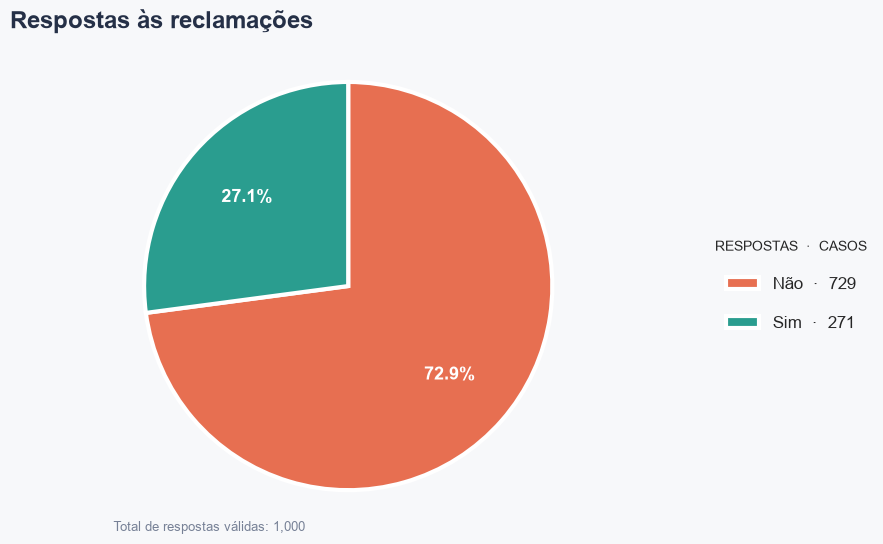

In [ ]:
ordem = ["Não", "Sim"]
contagens = df["Reclamação"].value_counts().reindex(ordem, fill_value=0)
total = contagens.sum()

if total == 0:
    raise ValueError("Não há respostas válidas na coluna 'Reclamação'.")

taxa_reclamacao = contagens["Sim"] / total * 100
print(f"Taxa de reclamação: {taxa_reclamacao:.1f}%")

cores = ["#E76F51", "#2A9D8F"]  # Não: vermelho | Sim: verde
rotulos = [f"Não  ·  {contagens['Não']:,}", f"Sim  ·  {contagens['Sim']:,}"]

fig, ax = plt.subplots(figsize=(9, 5.6), facecolor="#F7F8FA")
ax.set_facecolor("#F7F8FA")

fatias, _, percentuais = ax.pie(
    contagens,
    colors=cores,
    startangle=90,
    counterclock=False,
    autopct="%1.1f%%",
    pctdistance=0.66,
    wedgeprops={"edgecolor": "white", "linewidth": 3},
)

for texto in percentuais:
    texto.set_color("white")
    texto.set_fontsize(13)
    texto.set_fontweight("bold")

ax.set_title(
    "Respostas às reclamações",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#253047",
    pad=24,
)
ax.legend(
    fatias,
    rotulos,
    title="RESPOSTAS  ·  CASOS",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=12,
    title_fontsize=10,
    labelspacing=1.4,
)
ax.text(
    -1.15, -1.2,
    f"Total de respostas válidas: {total:,}",
    fontsize=9,
    color="#778196",
)

ax.axis("equal")
plt.tight_layout()
plt.show()

### KPIs

- 📦 **Total de entregas**: 6.097 entregas
- 📏 **Distância percorrida**: 232.322 km
- 🚚 **Total de viagens**: 1.000 viagens
- 📊 **Média de distância por entrega**: 65,49 km/entrega
- 📈 **Mediana de distância por entrega**: 51,00 km/entrega

O objetivo aqui é calcular alguns KPIs genéricos que conseguimos extrair da base de dados. Por exemplo:
- quantidade de entregas total: Soma da coluna `numero_entregas`
- quantidade de distância percorrida total: soma da coluna `Distância`
- numéro total de viagens: contagem do `ID_viagem`
- média de distância por entrega
- mediana da distância por entrega

In [37]:
df_kpi = raw_data.copy()

total_entregas = df_kpi["numero_entregas"].sum()
distancia_percorrida = df_kpi["Distância"].sum()
total_viagens = df_kpi["ID_viagem"].count()
media_distancia_entrega = (df_kpi["Distância"] / df_kpi["numero_entregas"]).mean()
mediana_distancia_entrega = (df_kpi["Distância"] / df_kpi["numero_entregas"]).median()

print(
    f"📦 Total de entregas: {total_entregas:,.0f} entregas\n"
    f"📏 Distância percorrida: {distancia_percorrida:,.2f} km\n"
    f"🚚 Total de viagens: {total_viagens:,.0f} viagens"
    f"\n📊 Média de distância por entrega: {media_distancia_entrega:,.2f} km/entrega"
    f"\n📈 Mediana de distância por entrega: {mediana_distancia_entrega:,.2f} km/entrega"
)

📦 Total de entregas: 6,097 entregas
📏 Distância percorrida: 232,322.00 km
🚚 Total de viagens: 1,000 viagens
📊 Média de distância por entrega: 65.49 km/entrega
📈 Mediana de distância por entrega: 51.00 km/entrega


### Razão Distância/Parada

A distância por parada foi, em média, de 51 km, com mediana de 44,30 km. Os 50% centrais dos registros ficaram entre 26 e 67 km por parada. Os valores mais extremos, como o máximo de 369 km por parada, ocorrem em viagens longas com poucas paradas registradas fora das entregas. No exemplo analisado, foram feitas várias entregas em um único dia, mas apenas uma parada foi contabilizada nessa variável. Como as paradas para entrega são registradas separadamente, essa combinação eleva a razão. Isso descreve o padrão dos dados, mas não permite concluir por que o motorista fez poucas paradas adicionais.

A métrica distância por parada indica **quantos quilômetros o motorista percorre, em média, para cada parada realizada durante a viagem**. Ela foi criada para iniciar um estudo sobre como as paradas estão distribuídas e apoiar uma avaliação futura da necessidade de pausas para descanso.

Atualmente, a empresa **não estabelece um número obrigatório de paradas para descanso**. As paradas são contabilizadas na variável número de paradas do motorista, mas não precisam ter um motivo específico registrado. Assim, essa contagem pode incluir pausas para descanso ou necessidades pessoais, bem como paradas extras causadas por emergências, problemas de saúde ou falhas no caminhão ou na carga. As paradas para entrega são registradas separadamente na variável número de entregas.

O estudo busca entender melhor essa necessidade e, futuramente, avaliar a definição de paradas obrigatórias para descanso. Essa eventual orientação deve permitir também paradas extras sempre que necessário, por exemplo, em caso de emergência ou falha mecânica.

$$
\
\text{Distância por parada (km/parada)} =
\frac{\text{Distância da viagem (km)}}
{\text{Número de paradas do motorista}}
\
$$

Como os motivos das paradas não são especificados, a métrica descreve a relação entre distância e quantidade de paradas, mas não mede diretamente o cansaço do motorista nem identifica a finalidade de cada parada.


========= Estatísticas Descritivas da Variável 'distancia/parada' =========



count    1000.000000
mean       51.223496
std        37.240502
min         7.142857
25%        26.150000
50%        44.291667
75%        67.000000
max       369.000000
Name: distancia/parada, dtype: float64

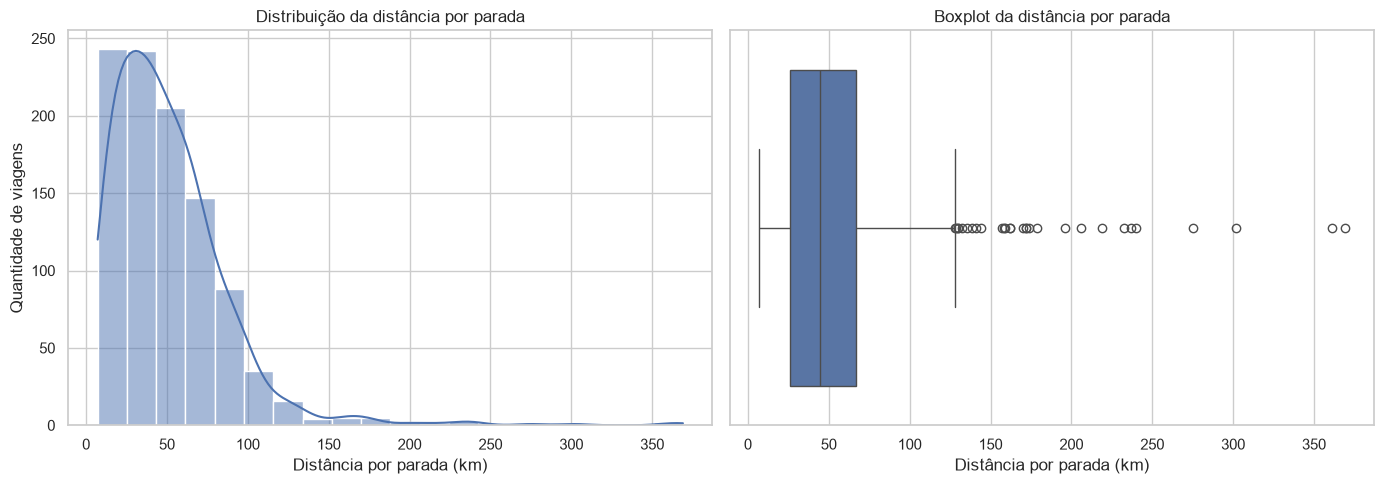

In [33]:
# Calculando a variável "distancia/parada"
df["distancia/parada"] = df["Distância"] / df["numero_paradas_motorista"].replace(0, np.nan)

# Estatísticas descritivas da variável "distancia/parada"
print("\n========= Estatísticas Descritivas da Variável 'distancia/parada' =========\n")
display(df["distancia/parada"].describe())

# visualização da distribuição da variável "distancia/parada" com histograma e boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma
sns.histplot(
    df["distancia/parada"],
    bins=20,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribuição da distância por parada")
axes[0].set_xlabel("Distância por parada (km)")
axes[0].set_ylabel("Quantidade de viagens")

# Boxplot horizontal
sns.boxplot(
    x=df["distancia/parada"],
    ax=axes[1]
)
axes[1].set_title("Boxplot da distância por parada")
axes[1].set_xlabel("Distância por parada (km)")

plt.tight_layout()
plt.show()

Com esses resultados, podemos descrever a distribuição da distância por parada nas 1.000 observações:
- A média é de 51,22 km por parada; a mediana é 44,29 km por parada. Ou seja, metade dos registros está abaixo de aproximadamente 44,29 km por parada e metade acima.
- O primeiro quartil é 26,15 km e o terceiro é 67 km. Assim, os 50% centrais dos registros ficam entre esses valores.
- O desvio-padrão de 37,24 km indica bastante variação entre os registros. O mínimo é 7,14 km por parada.
- **O valor máximo (369) merece ser investigado**. Ele pode representar uma viagem longa com poucas paradas, mas também pode decorrer de um registro atípico ou de uma situação operacional específica.

Para investigar o valor máximo, vamos verificar o salto entre o Q3 e o valor máximo analisando os percentis 80, 90, 95 e 99.

In [29]:
percentis = df["distancia/parada"].quantile([0.80, 0.90, 0.95, 0.99])

print("Percentis da distância por parada (km):")
for percentil, valor in percentis.items():
    print(f"P{int(percentil * 100)}: {valor:.2f} km")

Percentis da distância por parada (km):
P80: 72.92 km
P90: 90.70 km
P95: 107.29 km
P99: 178.67 km


Os percentis ajudam a detalhar a parte superior da distribuição de distância por parada:
- **P80 = 72,92 km**: 80% dos registros têm valor igual ou inferior a esse; 20% estão acima.
- **P90 = 90,70 km**: 90% estão nesse valor ou abaixo; 10% estão acima.
- **P95 = 107,29 km**: 95% estão nesse valor ou abaixo; 5% estão acima.
- **P99 = 178,67 km**: 99% estão nesse valor ou abaixo; 1% estão acima.

**O máximo de 369 km está ainda acima do P99** e, portanto, entre os valores mais extremos da amostra. Isso indica que vale investigar os registros nessa faixa e verificar quantas paradas foram contabilizadas e qual foi a distância da viagem.

In [35]:
df_filtrado = df[df["distancia/parada"] > df["distancia/parada"].quantile(0.99)]
df_filtrado

,numero_entregas,tipo_caminhao,produto,Distância,numero_dias,numero_paradas_motorista,Reclamação,faixa_distancia,distancia/parada
172,3,Tanque médio,Produto A,240,1,1,Não,150-249,240.0
376,6,Tanque pequeno,Produto B,275,1,1,Não,250-349,275.0
386,2,Tanque médio,Produto A,219,1,1,Não,150-249,219.0
417,5,Tanque grande,Produto A,206,1,1,Sim,150-249,206.0
499,2,Tanque pequeno,Produto D,302,1,1,Não,250-349,302.0
608,5,Tanque médio,Produto B,369,1,1,Não,350-449,369.0
609,3,Tanque médio,Produto A,237,1,1,Não,150-249,237.0
625,3,Tanque grande,Produto B,588,1,3,Não,550-649,196.0
667,2,Tanque médio,Produto D,465,1,2,Sim,450-549,232.5
859,6,Tanque médio,Produto B,361,1,1,Não,350-449,361.0


Analisando os padrões nos registros acima do P99, foi observado 10 casos. Alguns padrões foram observados:
- **Todos os registros têm `numero_dias = 1`**. Portanto, nesses dados, os valores altos da métrica aparecem em viagens registradas como ocorridas em um dia.
- **8 dos 10 casos (80%) têm apenas uma parada**. Os outros dois têm duas e três paradas. Como a razão é calculada dividindo a distância pelo número de paradas, poucas paradas em viagens longas contribuem diretamente para valores altos.
- **As distâncias variam de 206 a 588 km**. O maior valor da métrica, 369 km por parada, corresponde a uma viagem de 369 km com uma parada.
- **Há 8 casos sem reclamação e 2 com reclamação**. Isso, isoladamente, não permite concluir que a distância por parada esteja relacionada à ocorrência de reclamações.
- **Os produtos são A e B, com 4 casos cada, e D, com 2 casos**. Não há registros do produto C entre esses 10 casos.

O padrão mais evidente é a combinação de viagem de um dia, distância elevada e poucas paradas. Para entender melhor esses casos, seria útil verificar a duração real das viagens, os horários e motivos das paradas e se a contagem de paradas foi registrada corretamente. Como os motivos não são especificados, não dá para afirmar que esses registros indiquem cansaço ou falta de descanso.

# 4. Considerações Finais

O notebook analisou 1.000 viagens realizadas ao longo de três meses, considerando entregas, tipo de caminhão, produto, distância, duração, paradas do motorista e reclamações. A análise começou com verificações de qualidade e estatísticas descritivas e, em seguida, respondeu às perguntas de negócio com **boxplots**, **gráfico de dispersão**, **correlação de Pearson**, **tabelas de frequência**, **Information Value (IV)** e **eta ao quadrado (η²)**. Também calculou **indicadores gerais** e explorou a distância por parada.

Como próximos passos, recomenda-se validar com a área de negócio os registros extremos — em especial viagens com 50 entregas e os casos com distância por parada acima do P99 — e esclarecer como são definidos e registrados reclamações, distâncias e paradas. Também é importante investigar os motivos e a gravidade das reclamações por produto, comparar as taxas com períodos ou metas históricas e, quando houver dados suficientes, avaliar se as diferenças persistem em grupos comparáveis de rota, cliente e tipo de caminhão. As associações observadas são descritivas e, por si só, não demonstram relações de causa e efeito.